# Workshop #2: Silver Layer Parquet Exploration & Verification
**Course:** Data Analysis Programming — Semester 2026-I  
**Professor:** Eng. Carlos Andrés Sierra, M.Sc.  
**Institution:** Universidad Distrital Francisco José de Caldas  
**Team 7:** Samuel Alberto Leal Saenz, Cristian Andres Gámez Nuñez, Sara Nicolle Martínez Moreno  
**Topic:** Landslide Monitoring and Risk in Colombia

---

## 1. Introduction and Objectives
This notebook demonstrates how to load, inspect, and evaluate the standardized **Silver Layer Parquet files** generated by the Apache Airflow processing pipeline.

In this notebook, we verify:
1. **Schema Enforcement & PyArrow Metadata:** Correct data types (UTC timestamps, floats, categories).
2. **Null Handling & Imputation:** Audit of missing values and sentinel/imputation flags.
3. **Outlier Detection Analysis:** Statistical evaluation using IQR and Z-score methods.
4. **NLP Text Preprocessing Audit:** Token frequencies, stopword removal, and vocabulary in disaster narratives.
5. **End-to-End Data Lineage:** Verification of `_bronze_source_file`, `_processed_at_utc`, and deterministic `_record_hash`.


In [1]:
import pathlib
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import json

SILVER_DIR = pathlib.Path('../datalake_silver')
if not SILVER_DIR.exists():
    SILVER_DIR = pathlib.Path('datalake_silver')

parquet_files = sorted(list(SILVER_DIR.glob('*.parquet')))
print(f'Total Silver Parquet files detected: {len(parquet_files)}')
for f in parquet_files:
    print(f' - {f.name} ({f.stat().st_size / 1024:.1f} KB)')


Total Silver Parquet files detected: 7
 - landslides_20261117_000000.parquet (167.9 KB)
 - landslides_20261117_015701.parquet (178.1 KB)
 - lhasa_hazard_20261116_180000.parquet (14.8 KB)
 - lhasa_hazard_20261117_015702.parquet (16.4 KB)
 - rainfall_20261116_120000.parquet (96.8 KB)
 - rainfall_20261117_014917.parquet (96.8 KB)
 - rainfall_20261117_015702.parquet (98.8 KB)


## 2. Inspecting Rainfall Silver Data (`rainfall_*.parquet`)
We select the latest rainfall Parquet file and inspect its schema, column types, and embedded PyArrow metadata.


In [2]:
rainfall_files = [f for f in parquet_files if 'rainfall' in f.name]
assert len(rainfall_files) > 0, 'No rainfall parquet file found'
target_rainfall = rainfall_files[-1]

# Read PyArrow schema metadata
schema_meta = pq.read_metadata(target_rainfall)
print('--- PyArrow File Metadata ---')
print(f'Rows: {schema_meta.num_rows:,}')
print(f'Columns: {schema_meta.num_columns}')
print(f'Custom Metadata: {schema_meta.metadata}')

# Load into Pandas
df_rain = pd.read_parquet(target_rainfall)
print('\n--- DataFrame Info ---')
print(df_rain.info())
df_rain.head()


--- PyArrow File Metadata ---
Rows: 1,200
Columns: 16
Custom Metadata: {b'pandas': b'{"index_columns": [], "column_indexes": [], "columns": [{"name": "station_name", "field_name": "station_name", "pandas_type": "categorical", "numpy_type": "int8", "metadata": {"num_categories": 10, "ordered": false}}, {"name": "department", "field_name": "department", "pandas_type": "categorical", "numpy_type": "int8", "metadata": {"num_categories": 10, "ordered": false}}, {"name": "latitude", "field_name": "latitude", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "longitude", "field_name": "longitude", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "elevation_m", "field_name": "elevation_m", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "precipitation_mm", "field_name": "precipitation_mm", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "rain_mm", "field_name": "rain_mm", "p

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   station_name           1200 non-null   category           
 1   department             1200 non-null   category           
 2   latitude               1200 non-null   float64            
 3   longitude              1200 non-null   float64            
 4   elevation_m            1200 non-null   float64            
 5   precipitation_mm       1200 non-null   float64            
 6   rain_mm                1200 non-null   float64            
 7   soil_moisture_m3m3     1200 non-null   float64            
 8   timestamp              1200 non-null   datetime64[ns, UTC]
 9   soil_moisture_imputed  1200 non-null   bool               
 10  precip_outlier_iqr     1200 non-null   bool               
 11  precip_outlier_zscore  1200 non-null   bool               
 12  pre

None


,station_name,department,latitude,longitude,elevation_m,precipitation_mm,rain_mm,soil_moisture_m3m3,timestamp,soil_moisture_imputed,precip_outlier_iqr,precip_outlier_zscore,precip_zscore,_bronze_source_file,_processed_at_utc,_record_hash
0,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.196,2026-11-15 00:00:00+00:00,False,False,False,-0.372,openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,b9869628698746514bf798992ca4b3dac1cff381cd498d...
1,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.195,2026-11-15 01:00:00+00:00,False,False,False,-0.372,openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,37ce12b6a562489dcaa0db19cfb3e3c05b6c667aa46da2...
2,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.195,2026-11-15 02:00:00+00:00,False,False,False,-0.372,openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,bb6c479eeb7e23c3986dc61cbffae04bfbf501a2d8c9ea...
3,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.195,2026-11-15 03:00:00+00:00,False,False,False,-0.372,openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,478e28bcee3490aa58768cd5328f1e82ddab1bda049727...
4,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.195,2026-11-15 04:00:00+00:00,False,False,False,-0.372,openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,d7703f5d18c809f80c750c85d64a105c68f3821ea26d46...


## 3. Preprocessing Audit: Null Handling & Imputation
We verify that no nulls remain in critical coordinates or timestamps, and check the soil moisture imputation flag.


In [3]:
print('Null values per column in Silver Rainfall:')
print(df_rain.isna().sum())

print('\nSoil Moisture Imputation Distribution:')
print(df_rain['soil_moisture_imputed'].value_counts(normalize=True).round(3))


Null values per column in Silver Rainfall:
station_name             0
department               0
latitude                 0
longitude                0
elevation_m              0
precipitation_mm         0
rain_mm                  0
soil_moisture_m3m3       0
timestamp                0
soil_moisture_imputed    0
precip_outlier_iqr       0
precip_outlier_zscore    0
precip_zscore            0
_bronze_source_file      0
_processed_at_utc        0
_record_hash             0
dtype: int64

Soil Moisture Imputation Distribution:
soil_moisture_imputed
False    1.0
Name: proportion, dtype: float64


## 4. Outlier Detection Evaluation (IQR vs Z-Score)
We evaluate the precipitation outliers detected by the pipeline. In landslide monitoring, extreme rainfall events are critical hazard indicators.


In [4]:
print('--- Outlier Counts on Precipitation ---')
print(f"IQR Outliers: {df_rain['precip_outlier_iqr'].sum()} ({df_rain['precip_outlier_iqr'].mean()*100:.2f}%)")
print(f"Z-Score Outliers (|Z| > 3): {df_rain['precip_outlier_zscore'].sum()} ({df_rain['precip_outlier_zscore'].mean()*100:.2f}%)")

top_precip = df_rain.sort_values('precipitation_mm', ascending=False)[
    ['station_name', 'department', 'timestamp', 'precipitation_mm', 'precip_zscore', 'precip_outlier_iqr']
].head(10)
print('\nTop 10 Precipitation Readings:')
top_precip


--- Outlier Counts on Precipitation ---
IQR Outliers: 127 (10.58%)
Z-Score Outliers (|Z| > 3): 25 (2.08%)

Top 10 Precipitation Readings:


,station_name,department,timestamp,precipitation_mm,precip_zscore,precip_outlier_iqr
522,Pereira,Risaralda,2026-11-16 18:00:00+00:00,9.1,14.376,True
1059,Mocoa,Putumayo,2026-11-19 03:00:00+00:00,6.0,9.352,True
907,Pasto,Narino,2026-11-17 19:00:00+00:00,5.6,8.704,True
163,Medellin,Antioquia,2026-11-16 19:00:00+00:00,5.0,7.731,True
96,Bogota,Cundinamarca,2026-11-19 00:00:00+00:00,4.3,6.597,True
335,Cali,Valle del Cauca,2026-11-18 23:00:00+00:00,4.2,6.435,True
523,Pereira,Risaralda,2026-11-16 19:00:00+00:00,4.0,6.111,True
992,Mocoa,Putumayo,2026-11-16 08:00:00+00:00,3.5,5.300,True
524,Pereira,Risaralda,2026-11-16 20:00:00+00:00,3.5,5.300,True
860,Pasto,Narino,2026-11-15 20:00:00+00:00,3.4,5.138,True


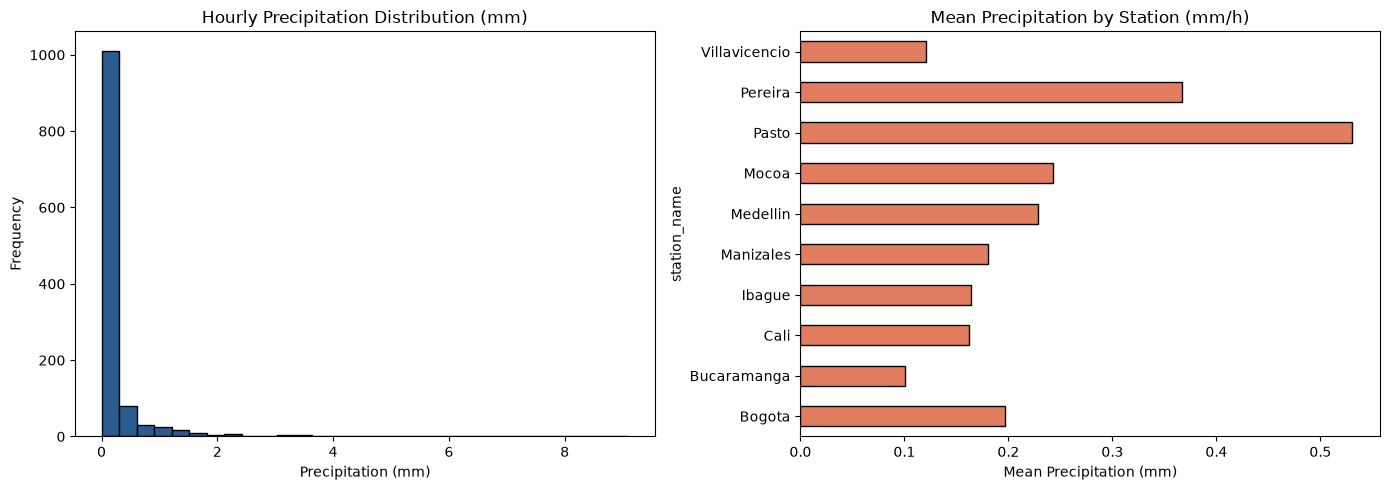

In [5]:
# Distribution plot of hourly precipitation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_rain['precipitation_mm'].plot(kind='hist', bins=30, ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Hourly Precipitation Distribution (mm)')
axes[0].set_xlabel('Precipitation (mm)')
axes[0].set_ylabel('Frequency')

# Average precipitation per station
df_rain.groupby('station_name', observed=True)['precipitation_mm'].mean().plot(
    kind='barh', ax=axes[1], color='#e27d60', edgecolor='black'
)
axes[1].set_title('Mean Precipitation by Station (mm/h)')
axes[1].set_xlabel('Mean Precipitation (mm)')

plt.tight_layout()
plt.show()


## 5. NLP Text Preprocessing on Landslide Narratives (`landslides_*.parquet`)
We load the historical landslide inventory to inspect the NLP pipeline results: cleaned text, removed stopwords, and token frequency distributions.


In [6]:
landslide_files = [f for f in parquet_files if 'landslides' in f.name]
assert len(landslide_files) > 0, 'No landslides parquet file found'
target_landslides = landslide_files[-1]

df_landslides = pd.read_parquet(target_landslides)
print(f'Loaded {len(df_landslides)} landslide records.')
print('Columns:', list(df_landslides.columns))

# Display comparison of raw vs cleaned NLP text
sample_nlp = df_landslides[['country_name', 'admin_division_name', 'raw_text_narrative', 'cleaned_text_nlp', 'token_count']].head(5)
sample_nlp


Loaded 109 landslide records.
Columns: ['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude', 'event_date_parsed', 'timestamp_utc', 'raw_text_narrative', 'cleaned_text_nlp', 'tokens_nlp', 'token_count', 'fatality_outlier_iqr', 'fatality_outlier_zscore', 'fatality_zscore', '_bronze_source_file', '_processed_at_utc', '_record_hash']


,country_name,admin_division_name,raw_text_narrative,cleaned_text_nlp,token_count
0,Colombia,Risaralda,"Dosquebradas, Risaralda The explosion at a pip...",dosquebradas risaralda the explosion at a pipe...,16
1,Colombia,Santander,"California village, Sutara valley, NE of Bucar...",california village sutara valley ne of bucaram...,64
2,Colombia,Nariño,"San Antonio(?) de Chuza, El Tambo, Narino The ...",san antonio de chuza el tambo narino the death...,56
3,Colombia,Huila,bus route from Neiva to San Vicente According ...,bus route from neiva to san vicente according ...,26
4,Colombia,Córdoba,"San Juan , Cordoba province BOGOTA, April 24 (...",san juan cordoba province bogota april upi a m...,48


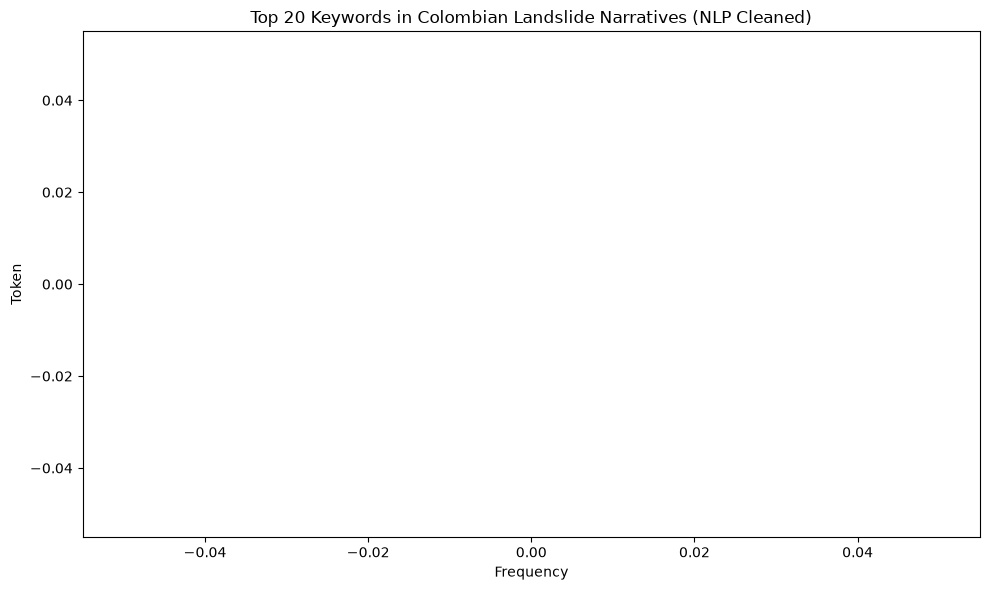

In [7]:
from collections import Counter

all_tokens = []
for token_list in df_landslides['tokens_nlp']:
    if isinstance(token_list, (list, tuple)):
        all_tokens.extend(token_list)

token_counts = Counter(all_tokens).most_common(20)
token_df = pd.DataFrame(token_counts, columns=['Keyword', 'Frequency'])

plt.figure(figsize=(10, 6))
plt.barh(token_df['Keyword'][::-1], token_df['Frequency'][::-1], color='#41b3a3', edgecolor='black')
plt.title('Top 20 Keywords in Colombian Landslide Narratives (NLP Cleaned)')
plt.xlabel('Frequency')
plt.ylabel('Token')
plt.tight_layout()
plt.show()


## 6. NASA LHASA Hazard Scraped Index (`lhasa_hazard_*.parquet`)
We inspect the Silver dataset containing scraped raster files, issue timestamps, and file sizes.


In [8]:
lhasa_files = [f for f in parquet_files if 'lhasa' in f.name]
assert len(lhasa_files) > 0, 'No LHASA parquet file found'
df_lhasa = pd.read_parquet(lhasa_files[-1])

print(f'LHASA Scraped Catalog: {len(df_lhasa)} rasters tracked.')
df_lhasa.head()


LHASA Scraped Catalog: 50 rasters tracked.


,file_name,url,nominal_issue_time,issue_code,context_text,discovered_at_utc,etag,last_modified,content_length_bytes,_bronze_source_file,_processed_at_utc,_record_hash
0,20261115T0000.tif,https://portal.nccs.nasa.gov/datashare/landsli...,2026-11-15 00:00:00+00:00,20261115T0000,"20261115T0000.tif 138.1 MiB November 16, 2026",2026-11-17T01:56:10.382070+00:00,"""6afb1c21-8a2453a""","Mon, 16 Nov 2026 15:07:13 GMT",144852282,nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,8c202a3df753b9a68f8dee2f54bd1eb80f46f1dd0c74ae...
1,20261114T0000.tif,https://portal.nccs.nasa.gov/datashare/landsli...,2026-11-14 00:00:00+00:00,20261114T0000,"20261114T0000.tif 138.8 MiB November 15, 2026",2026-11-17T01:56:10.382070+00:00,"""6af9caba-8ad3eb3""","Sun, 15 Nov 2026 15:07:38 GMT",145571507,nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,766fb33903ff91c79cc9cf319354dfab639e1dc6bb3c0e...
2,20261113T0000.tif,https://portal.nccs.nasa.gov/datashare/landsli...,2026-11-13 00:00:00+00:00,20261113T0000,"20261113T0000.tif 139.1 MiB November 14, 2026",2026-11-17T01:56:10.382070+00:00,"""6af8794a-8b21325""","Sat, 14 Nov 2026 15:07:54 GMT",145888037,nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,797f40d74d73a98aec818382db3a5894bc2b31e07ce4bf...
3,20261112T0000.tif,https://portal.nccs.nasa.gov/datashare/landsli...,2026-11-12 00:00:00+00:00,20261112T0000,"20261112T0000.tif 140.1 MiB November 13, 2026",2026-11-17T01:56:10.382070+00:00,unknown,unknown,0,nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,c4b78448c86597cb85c8ba3960d493f2328d369b55f98c...
4,20261111T0000.tif,https://portal.nccs.nasa.gov/datashare/landsli...,2026-11-11 00:00:00+00:00,20261111T0000,"20261111T0000.tif 140.2 MiB November 12, 2026",2026-11-17T01:56:10.382070+00:00,unknown,unknown,0,nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,29fd82b78ba0df42bae9326091ce88d04c08f89604f13f...


## 7. Data Lineage and Traceability Audit
Every record in the Silver layer must trace back to its origin in the Bronze layer.


In [9]:
lineage_summary = pd.DataFrame([
    {
        'Dataset': 'Rainfall (Open-Meteo)',
        'Bronze Source File': df_rain['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_rain['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_rain['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_rain),
    },
    {
        'Dataset': 'Landslides (NASA GLC)',
        'Bronze Source File': df_landslides['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_landslides['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_landslides['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_landslides),
    },
    {
        'Dataset': 'LHASA Hazard (NASA)',
        'Bronze Source File': df_lhasa['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_lhasa['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_lhasa['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_lhasa),
    },
])
lineage_summary


,Dataset,Bronze Source File,Processed At (UTC),Sample Record Hash,Total Rows
0,Rainfall (Open-Meteo),openmeteo_forecast_20261117_015625.json,2026-11-17 01:57:02.220532+00:00,b986962869874651...,1200
1,Landslides (NASA GLC),nasa_glc_20261117_015625.json,2026-11-17 01:57:01.838869+00:00,8a9ac8cbb0c62457...,109
2,LHASA Hazard (NASA),nasa_lhasa_20261117_015625.json,2026-11-17 01:57:02.062045+00:00,8c202a3df753b9a6...,50


## 8. Conclusion
The Silver layer implementation satisfies all Workshop #2 requirements:
- **Type safety:** Strict schemas enforced with PyArrow and Pandas.
- **Data Quality:** Outlier flags, null imputation, and deduplication applied deterministically.
- **NLP Readiness:** Cleaned narratives and token lists ready for semantic hazard classification.
- **Traceability:** Full lineage tracking from Bronze JSON to Silver Parquet.
